# Student Performance - Linear & Logistic Regression

**Goal:** use the Students Performance dataset to
1. **predict the math score** of a student (Linear Regression - a number), and
2. **predict if a student passes math or not** (Logistic Regression - yes / no).

**Dataset source:** Kaggle - *Students Performance in Exams* (1000 students, 8 columns)

**Steps in this notebook**

1. Load the data and have a first look
2. Data cleaning (missing values + duplicates)
3. Data visualisation with matplotlib and seaborn
4. Encoding the text columns + correlation
5. Linear Regression (train, test, evaluate)
6. Logistic Regression (train, test, evaluate)
7. Final summary

## 1. Load the data

In [9]:
! pip install pandas

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
! pip install numpy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
! pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
! pip install seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
! pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
# importing all the libraries i need
import warnings
warnings.filterwarnings("ignore")     # hides the yellow warning messages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# just making the charts look a bit nicer
sns.set_style("whitegrid")

In [15]:
# put the csv in the same folder as this notebook
# (in Google Colab: upload it from the Files panel on the left side)
data = pd.read_csv("StudentsPerformance.csv")
print(data)

     gender race/ethnicity parental level of education         lunch  \
0    female        group B           bachelor's degree      standard   
1    female        group C                some college      standard   
2    female        group B             master's degree      standard   
3      male        group A          associate's degree  free/reduced   
4      male        group C                some college      standard   
..      ...            ...                         ...           ...   
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
0                      none          72             72         

In [16]:
# first 5 rows - just to see how the data looks
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [17]:
# how many rows and columns do we have?
print("Rows    :", data.shape[0])
print("Columns :", data.shape[1])

Rows    : 1000
Columns : 8


In [18]:
# column names
data.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [19]:
# info() tells us the data types and if any value is missing (non-null count)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [20]:
# describe() gives the basic statistics of the number columns
# (count, mean, std, min, 25%, 50%, 75%, max)
data.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## 2. Data cleaning

In [21]:
# missing values - counting NaN in every column
data.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [22]:
# total missing values in the whole dataset
data.isnull().sum().sum()

np.int64(0)

There are **0 missing values**, so no need for `dropna()` or `fillna()` here. Now let's check duplicate rows.

In [23]:
# how many duplicate rows?
print("Duplicate rows before :", data.duplicated().sum())

# removing them (if there are any)
data = data.drop_duplicates()
print("Duplicate rows after  :", data.duplicated().sum())
print("Shape now             :", data.shape)

Duplicate rows before : 0
Duplicate rows after  : 0
Shape now             : (1000, 8)


In [24]:
# the column names have spaces and a slash, which is annoying to type
# so i am replacing them with underscores
data.columns = data.columns.str.replace(" ", "_").str.replace("/", "_")
data.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='str')

## 3. Data visualisation

### 3.1 How are the scores spread? (histogram)

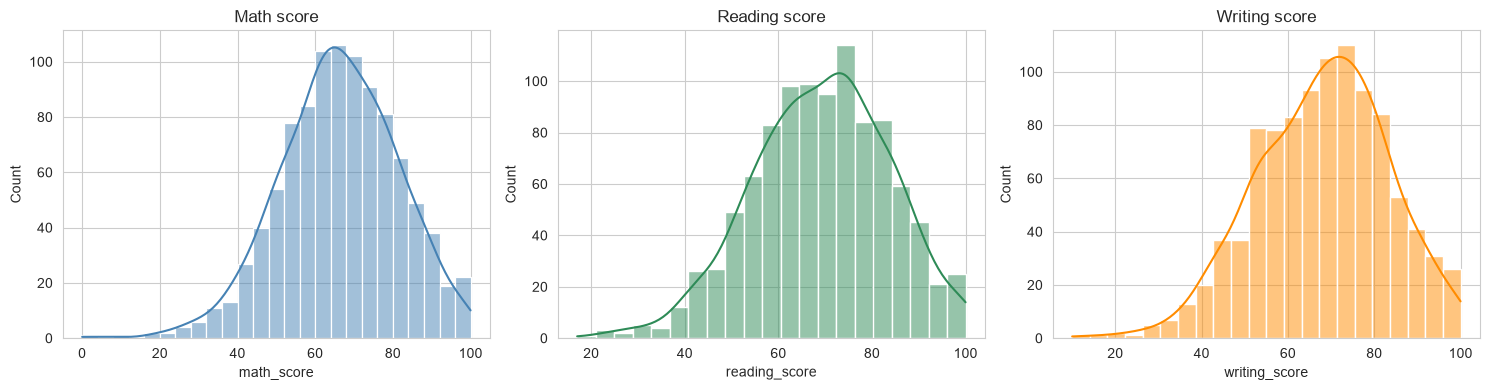

In [56]:
# 3 histograms side by side, one for each subject
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data["math_score"], kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Math score")

sns.histplot(data["reading_score"], kde=True, color="seagreen", ax=axes[1])
axes[1].set_title("Reading score")

sns.histplot(data["writing_score"], kde=True, color="darkorange", ax=axes[2])
axes[2].set_title("Writing score")

plt.tight_layout()
plt.show()

Most students score between 55 and 80 in every subject. The curves look close to a bell shape, with a few very low scores on the left.

### 3.2 Count of students in each category (countplot)

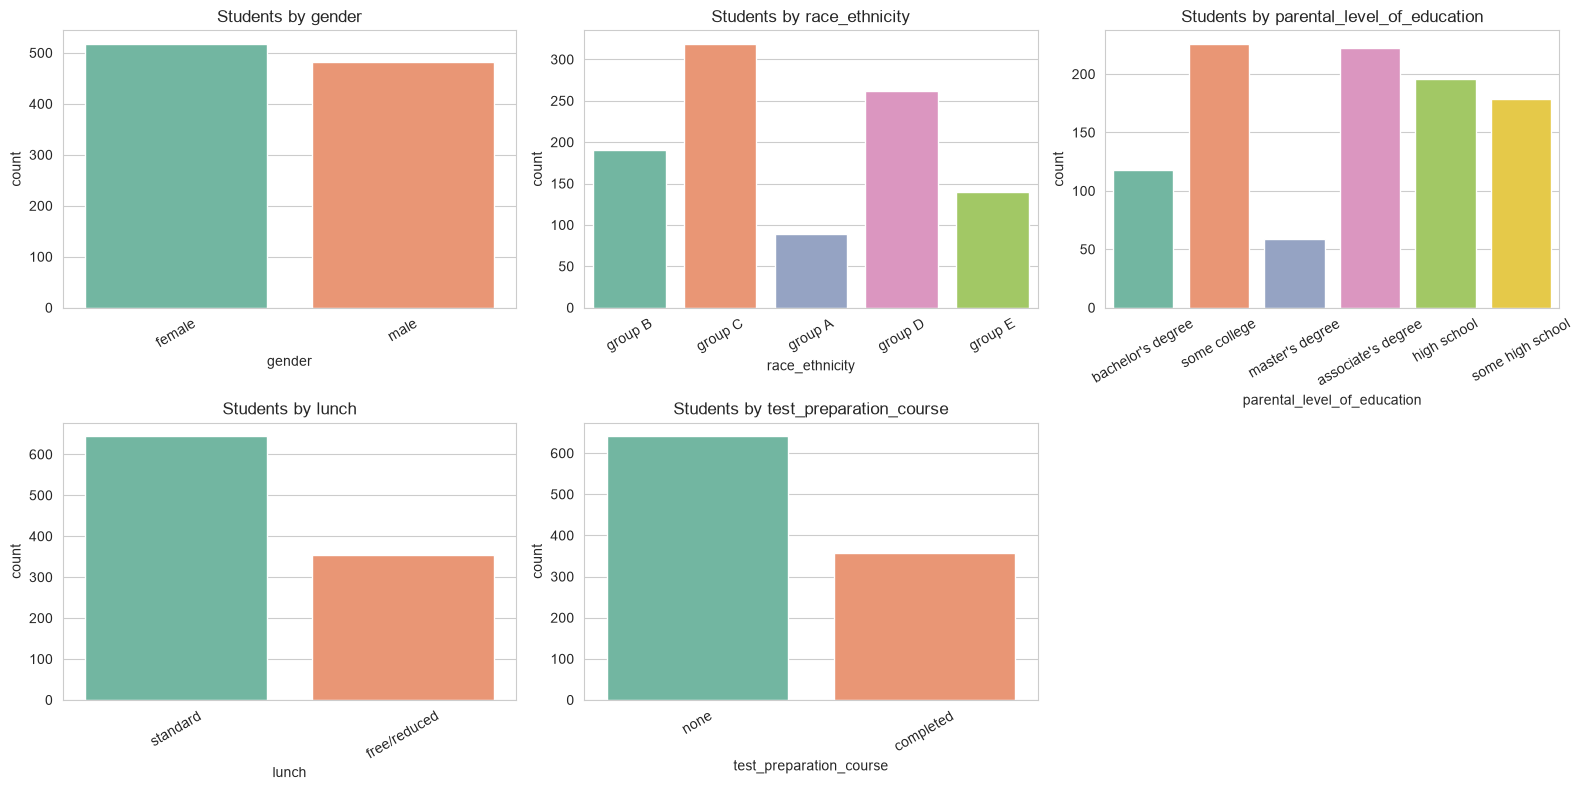

In [57]:
# the text columns we have
cat_cols = ["gender", "race_ethnicity", "parental_level_of_education",
            "lunch", "test_preparation_course"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=data, x=col, ax=axes[i], palette="Set2")
    axes[i].set_title("Students by " + col)
    axes[i].tick_params(axis="x", rotation=30)

axes[5].axis("off")      # 6th box is empty, so hide it
plt.tight_layout()
plt.show()

### 3.3 Does lunch type or test preparation change the math score? (boxplot)

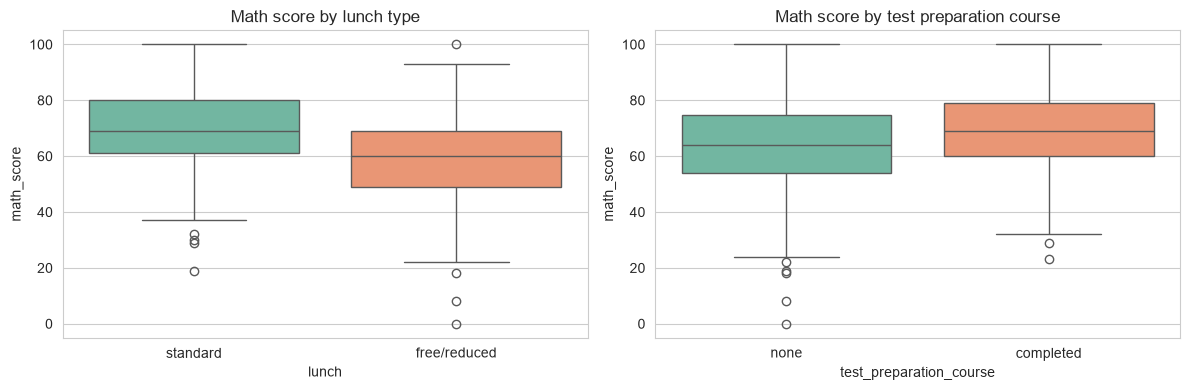

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=data, x="lunch", y="math_score", palette="Set2", ax=axes[0])
axes[0].set_title("Math score by lunch type")

sns.boxplot(data=data, x="test_preparation_course", y="math_score", palette="Set2", ax=axes[1])
axes[1].set_title("Math score by test preparation course")

plt.tight_layout()
plt.show()

Students with a **standard lunch** and students who **completed the test prep course** have a higher median math score.

### 3.4 Reading score vs math score (scatter plot with line)

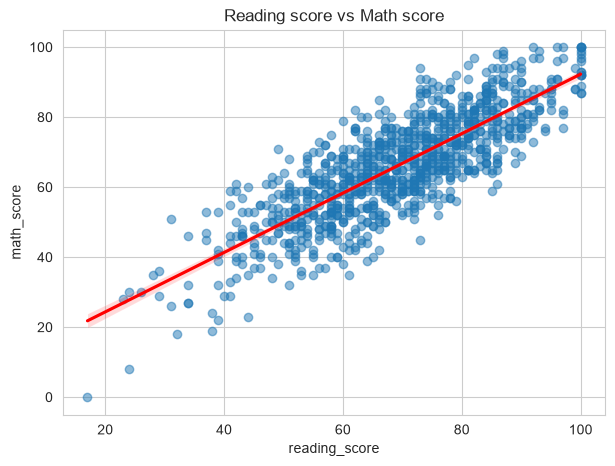

In [66]:
plt.figure(figsize=(7, 5))
sns.regplot(data=data, x="reading_score", y="math_score",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title("Reading score vs Math score")
plt.show()

The points go up in a straight-ish line, so students good at reading are usually good at math too. This is why linear regression should work well here.

### 3.5 Average math score by parents' education (bar chart)

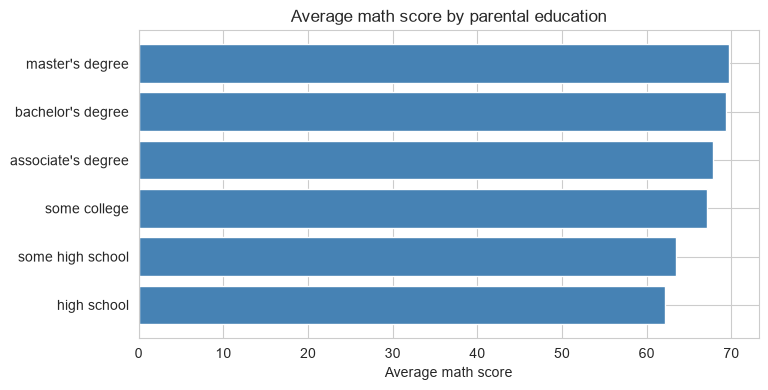

In [29]:
# matplotlib bar chart - first i find the average with groupby
avg_math = data.groupby("parental_level_of_education")["math_score"].mean().sort_values()

plt.figure(figsize=(8, 4))
plt.barh(avg_math.index, avg_math.values, color="steelblue")
plt.xlabel("Average math score")
plt.title("Average math score by parental education")
plt.show()

## 4. Encoding and correlation

Machine learning models only understand **numbers**, so the text columns (gender, lunch etc.) must be converted.
I am using **One-Hot Encoding** with `pd.get_dummies()`. `drop_first=True` removes one extra column per feature so the columns don't copy each other.

In [30]:
# one-hot encoding of all the text columns
data_encoded = pd.get_dummies(data, columns=cat_cols, drop_first=True)

# get_dummies gives True/False, i want 1/0
data_encoded = data_encoded.astype(int)

data_encoded.head()

,math_score,reading_score,writing_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,72,72,74,0,1,0,0,0,1,0,0,0,0,1,1
1,69,90,88,0,0,1,0,0,0,0,0,1,0,1,0
2,90,95,93,0,1,0,0,0,0,0,1,0,0,1,1
3,47,57,44,1,0,0,0,0,0,0,0,0,0,0,1
4,76,78,75,1,0,1,0,0,0,0,0,1,0,1,1


In [31]:
print("Columns before encoding:", data.shape[1])
print("Columns after encoding :", data_encoded.shape[1])

Columns before encoding: 8
Columns after encoding : 15


### Correlation - which columns are related to math score?

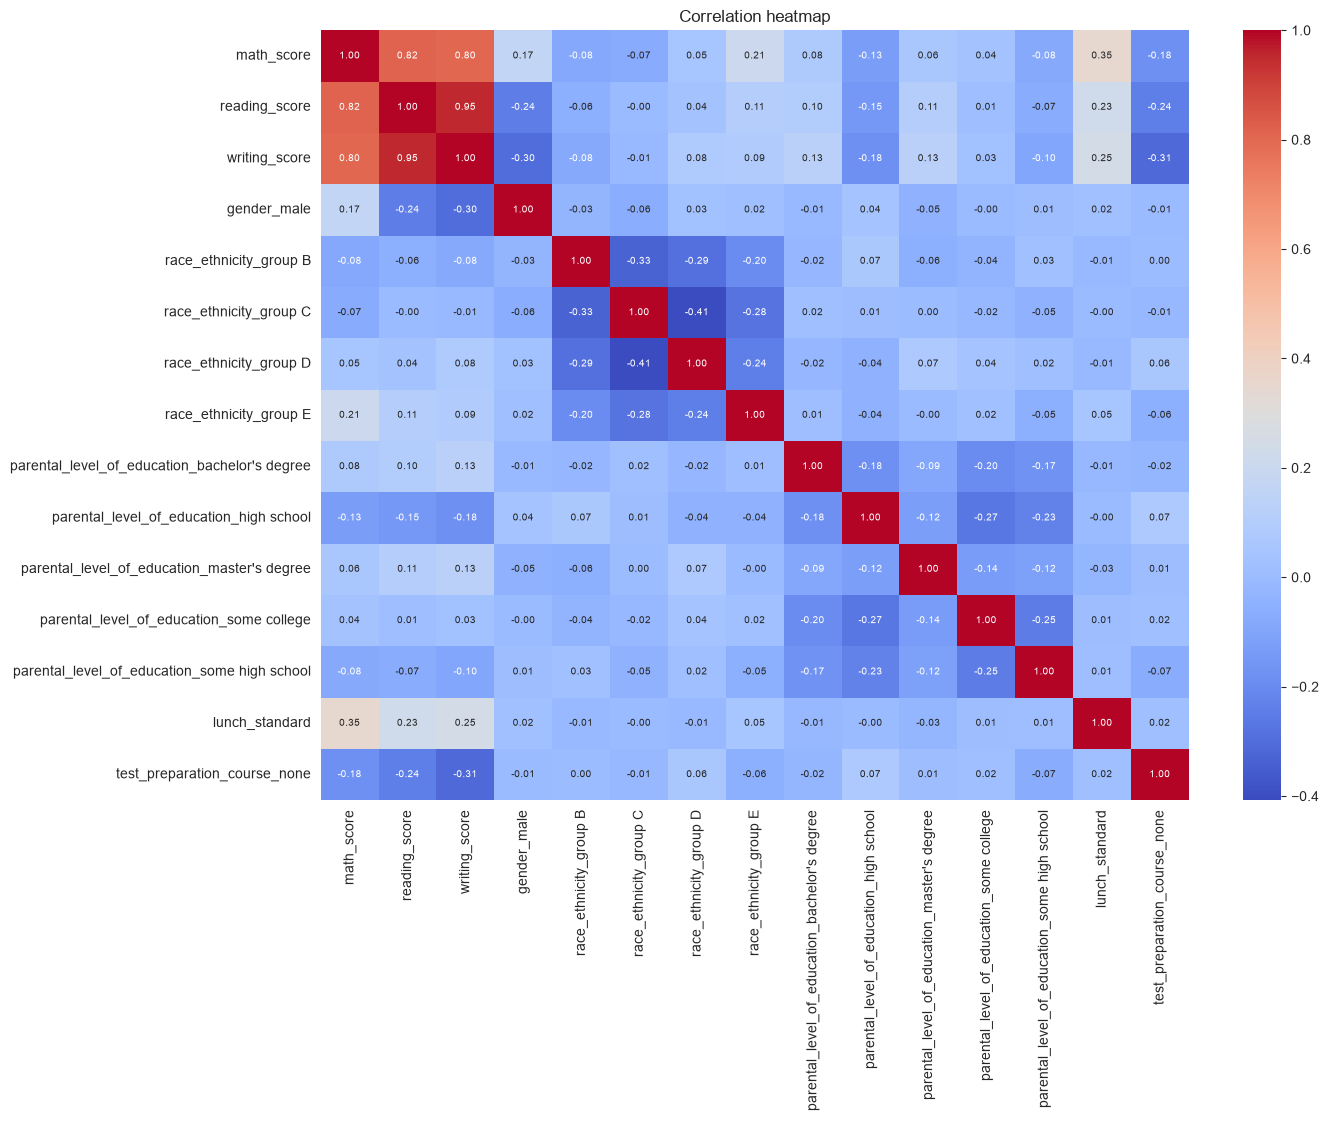

In [32]:
# heatmap of correlation between all the columns
plt.figure(figsize=(14, 10))
sns.heatmap(data_encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation heatmap")
plt.show()

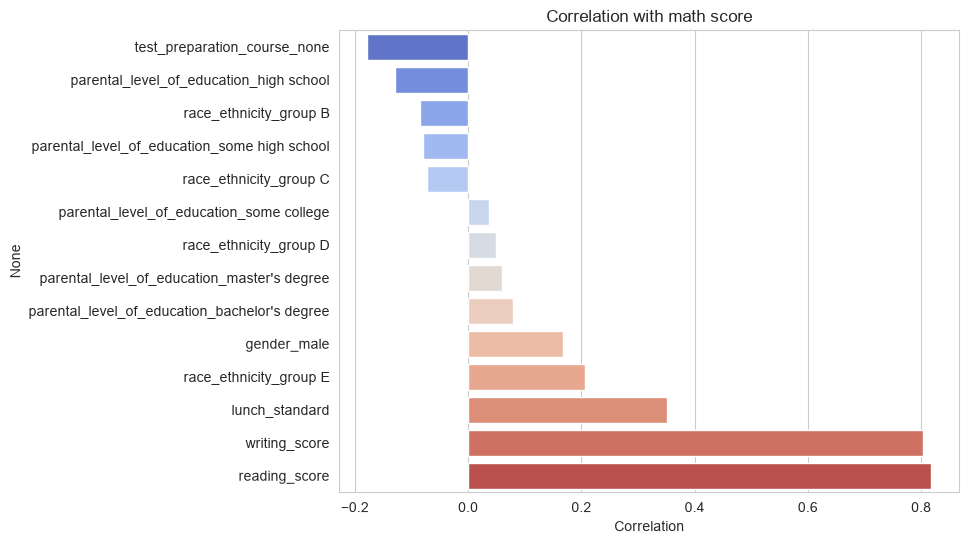

In [33]:
# correlation of every column with math score only (sorted)
corr_math = data_encoded.corr()["math_score"].drop("math_score").sort_values()

plt.figure(figsize=(8, 6))
sns.barplot(x=corr_math.values, y=corr_math.index, palette="coolwarm")
plt.title("Correlation with math score")
plt.xlabel("Correlation")
plt.show()

**What i noticed**

- `reading_score` (0.82) and `writing_score` (0.80) have a very strong relation with math score.
- `lunch_standard` (0.35) is the next best one.
- `reading_score` and `writing_score` are also strongly related to each other (0.95), so they carry almost the same information.

## 5. Linear Regression - predict the math score

Linear Regression is used when we want to predict a **number**. Here: the math score from 0 to 100.

### 5.1 Split into X and y

In [34]:
# y = what we want to predict, X = everything else we use to predict it
y = data_encoded["math_score"]
X = data_encoded.drop("math_score", axis=1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 14)
y shape: (1000,)


### 5.2 Train test split

In [35]:
# 80% data for training, 20% for testing
# random_state=42 so that i get the same split every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 800
Testing rows : 200


### 5.3 Train the model

In [36]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)
print("Model trained!")

Model trained!


In [37]:
# coefficients = how many marks the math score changes when that column goes up by 1
coef_table = pd.DataFrame({"feature": X.columns, "coefficient": lin_model.coef_})
coef_table = coef_table.sort_values("coefficient", ascending=False)

print("Intercept:", round(lin_model.intercept_, 2))
coef_table

Intercept: -10.91


,feature,coefficient
2,gender_male,13.064884
6,race_ethnicity_group E,4.892649
12,lunch_standard,3.510075
13,test_preparation_course_none,3.289642
10,parental_level_of_education_some college,0.998856
8,parental_level_of_education_high school,0.929312
11,parental_level_of_education_some high school,0.756470
1,writing_score,0.724148
3,race_ethnicity_group B,0.359323
0,reading_score,0.236023


### 5.4 Predict on test data and check the result

In [38]:
y_pred = lin_model.predict(X_test)

# comparing a few real values with the predicted ones
compare = pd.DataFrame({"actual": y_test.values, "predicted": y_pred.round(1)})
compare.head(10)

,actual,predicted
0,91,76.4
1,53,58.9
2,80,77.0
3,74,76.9
4,84,87.6
5,81,79.0
6,69,64.7
7,54,53.0
8,87,74.2
9,51,49.2


In [39]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print("MAE  (average mistake in marks) :", round(mae, 2))
print("MSE                             :", round(mse, 2))
print("RMSE                            :", round(rmse, 2))
print("R2 score                        :", round(r2, 3))

MAE  (average mistake in marks) : 4.21
MSE                             : 29.1
RMSE                            : 5.39
R2 score                        : 0.88


**How to read this**

- **MAE** - on average the prediction is off by this many marks.
- **RMSE** - same idea, but big mistakes are punished more.
- **R2 score** - how much of the ups and downs in math score the model explains. 1.0 is perfect, 0 is useless.

### 5.5 Charts for the linear regression

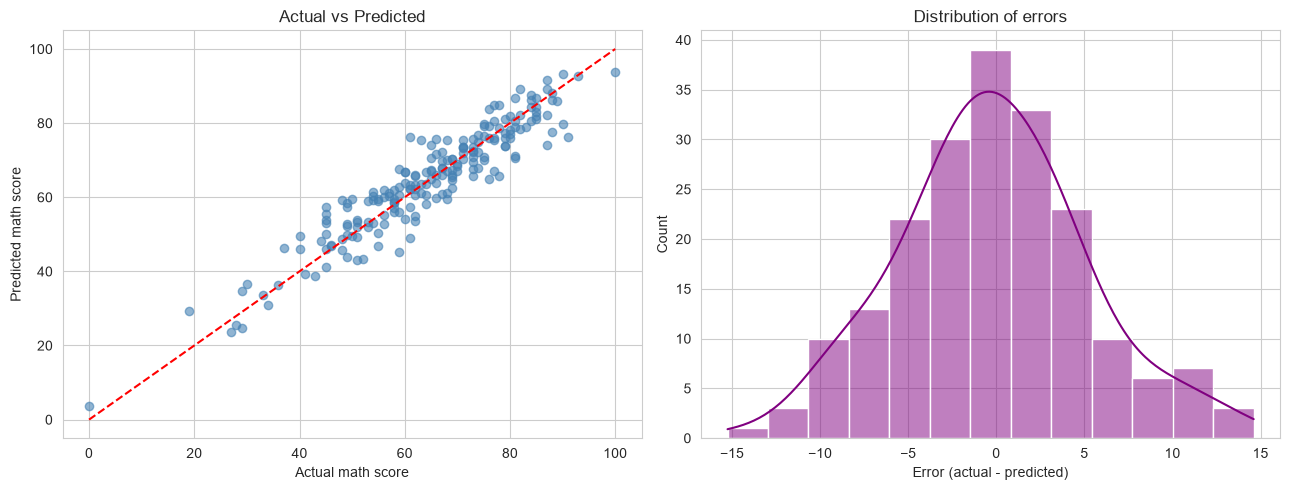

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# left: actual vs predicted, red dotted line = perfect prediction
axes[0].scatter(y_test, y_pred, alpha=0.6, color="steelblue")
axes[0].plot([0, 100], [0, 100], "r--")
axes[0].set_xlabel("Actual math score")
axes[0].set_ylabel("Predicted math score")
axes[0].set_title("Actual vs Predicted")

# right: errors (residuals) - should be around 0 and bell shaped
errors = y_test - y_pred
sns.histplot(errors, kde=True, color="purple", ax=axes[1])
axes[1].set_xlabel("Error (actual - predicted)")
axes[1].set_title("Distribution of errors")

plt.tight_layout()
plt.show()

The points are close to the red line and the errors are centred around 0, so the model is working fine.

## 6. Logistic Regression - will the student pass math?

Logistic Regression is used when the answer is a **category** (yes / no). So first we have to make a Pass / Fail column.
I decided that **math score >= 60 means Pass**. (You can change `PASS_MARK` and run again.)

In [41]:
PASS_MARK = 60

# 1 = pass, 0 = fail
data_encoded["passed_math"] = (data_encoded["math_score"] >= PASS_MARK).astype(int)

data_encoded["passed_math"].value_counts()

passed_math
1    677
0    323
Name: count, dtype: int64

In [42]:
# percentage of pass and fail
data_encoded["passed_math"].value_counts(normalize=True) * 100

passed_math
1    67.7
0    32.3
Name: proportion, dtype: float64

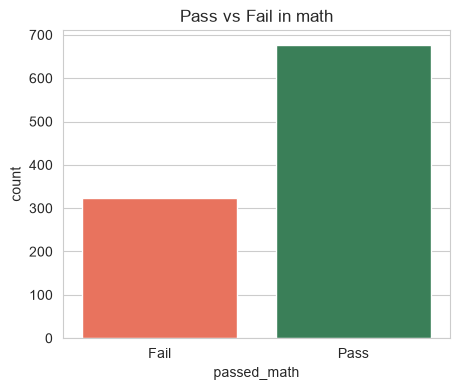

In [43]:
plt.figure(figsize=(5, 4))
sns.countplot(x=data_encoded["passed_math"], palette=["tomato", "seagreen"])
plt.xticks([0, 1], ["Fail", "Pass"])
plt.title("Pass vs Fail in math")
plt.show()

### 6.1 X, y and split

**Important:** i have to drop `math_score` from X. If it stays, the model can just see the answer and the result will be fake (this is called data leakage).

In [44]:
y_log = data_encoded["passed_math"]
X_log = data_encoded.drop(["math_score", "passed_math"], axis=1)

# stratify=y_log keeps the same pass/fail ratio in train and test
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log)

print("Training rows:", Xl_train.shape[0])
print("Testing rows :", Xl_test.shape[0])

Training rows: 800
Testing rows : 200


### 6.2 Train the model

In [45]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(Xl_train, yl_train)
print("Model trained!")

Model trained!


### 6.3 Predict and evaluate

In [46]:
yl_pred = log_model.predict(Xl_test)

# comparing a few actual and predicted values (1 = pass, 0 = fail)
pd.DataFrame({"actual": yl_test.values, "predicted": yl_pred}).head(10)

,actual,predicted
0,1,1
1,1,1
2,1,1
3,1,1
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,1,1


In [47]:
acc = accuracy_score(yl_test, yl_pred)
print("Accuracy :", round(acc * 100, 2), "%")

Accuracy : 89.5 %


In [48]:
# confusion matrix = how many predictions were right and wrong
cm = confusion_matrix(yl_test, yl_pred)
cm

array([[ 50,  15],
       [  6, 129]])

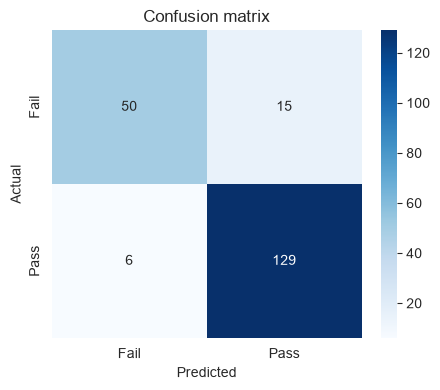

In [49]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

In [50]:
# precision, recall and f1-score for both classes
print(classification_report(yl_test, yl_pred, target_names=["Fail", "Pass"]))

              precision    recall  f1-score   support

        Fail       0.89      0.77      0.83        65
        Pass       0.90      0.96      0.92       135

    accuracy                           0.90       200
   macro avg       0.89      0.86      0.88       200
weighted avg       0.89      0.90      0.89       200



**How to read this**

- **Accuracy** - out of all test students, how many did we predict correctly.
- **Precision** - when the model says "Pass", how often is it really a pass.
- **Recall** - out of all the real passing students, how many did the model find.

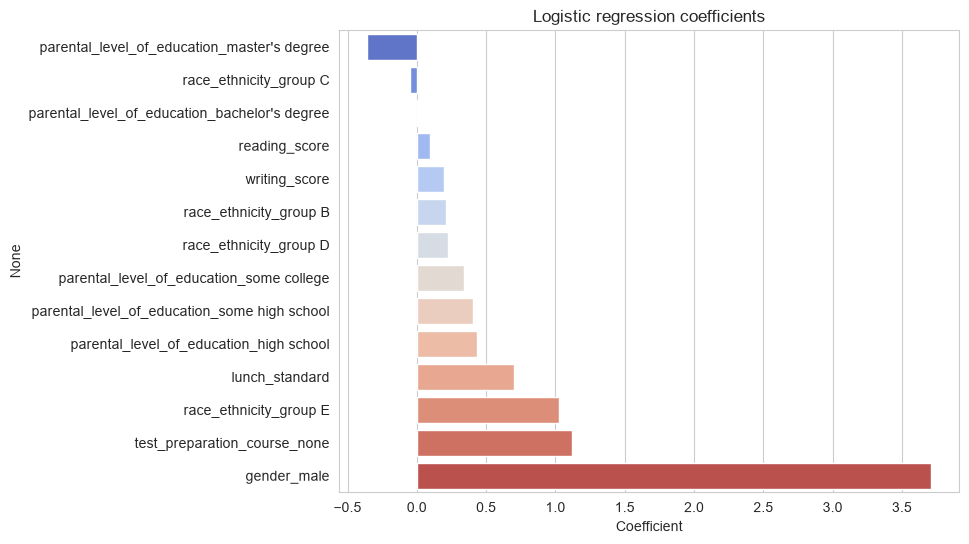

In [51]:
# which columns push the student towards pass? (positive = more chance to pass)
log_coef = pd.Series(log_model.coef_[0], index=X_log.columns).sort_values()

plt.figure(figsize=(8, 6))
sns.barplot(x=log_coef.values, y=log_coef.index, palette="coolwarm")
plt.title("Logistic regression coefficients")
plt.xlabel("Coefficient")
plt.show()

## 7. Try it on a new student

In [52]:
# making up a new student and asking both models about him
new_student = {
    "gender": "male",
    "race_ethnicity": "group C",
    "parental_level_of_education": "some college",
    "lunch": "standard",
    "test_preparation_course": "completed",
    "reading_score": 70,
    "writing_score": 68
}

# same encoding as before, then line up the columns exactly like training data
new_df = pd.DataFrame([new_student])
new_df = pd.get_dummies(new_df)
new_df = new_df.reindex(columns=X.columns, fill_value=0).astype(int)

print("Predicted math score :", round(lin_model.predict(new_df)[0], 1))

result = log_model.predict(new_df[X_log.columns])[0]
prob = log_model.predict_proba(new_df[X_log.columns])[0][1]
print("Will pass math?      :", "Yes" if result == 1 else "No")
print("Chance of passing    :", round(prob * 100, 1), "%")

Predicted math score : 71.8
Will pass math?      : Yes
Chance of passing    : 96.5 %


## 8. Final summary

In [53]:
print("LINEAR REGRESSION (predict math score)")
print("  R2 score :", round(r2, 3))
print("  MAE      :", round(mae, 2), "marks")
print("  RMSE     :", round(rmse, 2), "marks")
print()
print("LOGISTIC REGRESSION (predict pass / fail, pass mark =", PASS_MARK, ")")
print("  Accuracy :", round(acc * 100, 2), "%")

LINEAR REGRESSION (predict math score)
  R2 score : 0.88
  MAE      : 4.21 marks
  RMSE     : 5.39 marks

LOGISTIC REGRESSION (predict pass / fail, pass mark = 60 )
  Accuracy : 89.5 %


### Conclusion

- The dataset was clean: **no missing values and no duplicates**.
- Reading and writing scores are the strongest signals for math score. Lunch type and test preparation also matter a little.
- **Linear Regression** can predict the exact math score with a small average error, so a simple straight-line model is already good for this data.
- **Logistic Regression** can tell pass or fail correctly for most of the students.
- Limitation: only 1000 students, and the model shows *relation*, not *cause* (for example, lunch type does not directly make a student score more).